In [24]:
#Project set up

#All necessary packages
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import CelebA
from torchvision.models import resnet18, ResNet18_Weights
from torchmetrics.classification import BinaryAccuracy, BinaryAUROC, BinaryF1Score
import gc
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, mean_squared_error
from scipy.stats import pearsonr
import random

# Setting seed for reproducability across all packages
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # For multiple GPUs
    
    # Avoids dynamic tuning that varies based off hardware
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# Device configuration - will choose CPU for my setup
device = torch.device("cpu")
print(f"Active execution device: {device}")

# Global Hyperparameters
BATCH_SIZE = 64        # Number of training samples passed through the neural network on each forward/backward pass
LEARNING_RATE = 1e-3    # Use smaller learning rate as ResNet is pretrained. Default range for Adam Opt
REG_PARAM = 2e-5
FINAL_LAYER_PEN = 1e-4
NUM_EPOCHS = 5          # Number of training passes per part
DATA_DIR = "./data"
ELASTIC_NET = True
if ELASTIC_NET: EL_WEIGHT, L1_LAMBDA = (0.99, 1e-4)

# Target label
TARGET_ATTR = "Smiling"

# 10 Facial Attributes of Interest
CONCEPT_ATTRS = [
    "Mouth_Slightly_Open",
    "High_Cheekbones",
    "Chubby",
    "Narrow_Eyes",
    "Bags_Under_Eyes",
    "Big_Lips",
    "Big_Nose",
    "Pointy_Nose",
    "Bushy_Eyebrows",
    "Arched_Eyebrows",
]

# variable for concept quantity
NUM_CONCEPTS = len(CONCEPT_ATTRS) 

# Crops the image to reduce pixels for compute time and makes it square
transform = transforms.Compose([
    transforms.CenterCrop(178), #Crop first so PyTorch doesn't squish rectangular image into a square with Resize
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

# Load our datasets
full_train_ds = CelebA(root=DATA_DIR, split="train", target_type="attr", download=False, transform=transform)
full_test_ds  = CelebA(root=DATA_DIR, split="test",  target_type="attr", download=False, transform=transform)

# Subsampling dataset since I am using CPU
train_dataset = Subset(full_train_ds, list(range(5000)))
test_dataset  = Subset(full_test_ds, list(range(1000)))

# Grabbing the indices for the target and the concepts
target_y_idx = full_train_ds.attr_names.index(TARGET_ATTR)
concept_indices = [full_train_ds.attr_names.index(attr) for attr in CONCEPT_ATTRS]

print(f"Train subset size: {len(train_dataset)} | Test subset size: {len(test_dataset)}")

# Load in a pre-trained ResNet-18 Neural network and remove the final layer.
# Instead, final layer will output a vector of features, which we flatten
# to whatever dimension we need for our problem. Ex. 1 for "Smiling", 10 
# for all features of interest. 
class SharedResNetBackbone(nn.Module):
    """
    Base feature extractor class wrapping an ImageNet-pretrained ResNet-18 backbone.
    Strips off the default 1000-class fc layer, producing a 512-dimensional vector.
    """
    def __init__(self, pretrained=True):
        super(SharedResNetBackbone, self).__init__()
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        resnet = resnet18(weights=weights)
        
        self.in_features = resnet.fc.in_features  # 512 features
        
        # Remove original fc layer by slicing up to AvgPool2d
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

    def forward(self, x):
        features = self.backbone(x)
        return torch.flatten(features, 1)  # Output shape: (N, 512)

Active execution device: cpu
Train subset size: 5000 | Test subset size: 1000


In [25]:
# Helper function to output additional model metrics
"""
    - y_true: Ground truth values as a numpy array
    - y_pred_probs: Predicted probabilities as a numpy array (after sigmoid/softmax)
"""
def evaluate_predictions(y_true, y_pred_probs, threshold=0.5):
    # Must be numpy arrays
    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred_binary = (y_pred_probs >= threshold).astype(int)

    # Create dictionary to store metrics
    metrics = {}
    
    # Find accuracy via function
    metrics['accuracy'] = accuracy_score(y_true, y_pred_binary)
    
    # Calculate Root MSE
    metrics['rmse'] = np.sqrt(mean_squared_error(y_true, y_pred_probs))
    
    # AUROC
    try:
        if y_true.ndim > 1 and y_true.shape[1] > 1:
            metrics['auroc'] = roc_auc_score(y_true, y_pred_probs, average='macro')
        else:
            metrics['auroc'] = roc_auc_score(y_true, y_pred_probs)
    except ValueError:
        metrics['auroc'] = float('nan') # Edge case if only one class present in batch
        
    # F1 Score
    if y_true.ndim > 1 and y_true.shape[1] > 1:
        metrics['f1'] = f1_score(y_true, y_pred_binary, average='macro', zero_division=0)
    else:
        metrics['f1'] = f1_score(y_true, y_pred_binary, zero_division=0)
        
    # Pearson Correlation COefficient
    corrs = []
    if y_true.ndim > 1:
        for i in range(y_true.shape[1]):
            # Avoid constant columns where correlation is undefined
            if np.std(y_true[:, i]) > 0 and np.std(y_pred_probs[:, i]) > 0:
                r, _ = pearsonr(y_true[:, i], y_pred_probs[:, i])
                corrs.append(r)
        metrics['avg_pearson'] = np.mean(corrs) if corrs else 0.0
    else:
        if np.std(y_true) > 0 and np.std(y_pred_probs) > 0:
            metrics['avg_pearson'], _ = pearsonr(y_true, y_pred_probs)
        else:
            metrics['avg_pearson'] = 0.0
            
    # Sparsity: Measures interpretability
    metrics['sparsity_pct'] = float(np.mean(y_pred_binary) * 100)
    
    return metrics

In [26]:
#Part 1

# Custom collate function to extract 'Smiling' target vector
# This is used because CelebA includes large multidimensional images
# so we define a custom collate_fn to avoid returning all 40 attributes per 
# image and just the specific Smiling target label.
# Returns a tuple of the images and their corresponding target attribute
def baseline_collate_fn(batch):
    images, target_attrs = zip(*batch)
    images = torch.stack(images, dim=0)
    
    # Extract single target 'Smiling' and convert (-1, 1) -> (0.0, 1.0)
    raw_targets = torch.stack([attr[target_y_idx] for attr in target_attrs])
    targets = (raw_targets == 1).float().unsqueeze(1)  # Shape: (N, 1)
    
    return images, targets

# DataLoaders which automate feeding the data into the model.
# Creates a stack of images (size of which is batch_size = 64), where each image is 64x64 pixels with 3 color channels
train_loader_y = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=baseline_collate_fn)
test_loader_y  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=baseline_collate_fn)

# Going to use our pre-defined backbone class so we can 
# re-use the already trained model. Adds on a linear layer 
# so we can use it for our Smiling classification problem
# and produce a single output per image. This is not a probability yet
# because this is done later with BCEWithLogitsLoss() which applies the 
# sigmoid function.
class BaselineClassifier(nn.Module):
    def __init__(self, backbone, num_classes=1):
        super(BaselineClassifier, self).__init__()
        self.backbone = backbone
        self.classifier = nn.Linear(backbone.in_features, num_classes)

    def forward(self, x):
        features = self.backbone(x)
        return self.classifier(features)

# Instantiate Shared Backbone and Model
shared_backbone_1 = SharedResNetBackbone(pretrained=True)
baseline_model = BaselineClassifier(backbone=shared_backbone_1, num_classes=1).to(device)

criterion_y = nn.BCEWithLogitsLoss()  #Combines both the sigmoid function wtih the binary cross-entropy function
optimizer_y = optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE, weight_decay=REG_PARAM)  #Instead of SGD, Adam computes individual learning rate per parameter

# Training Loop
print("\n=== Part 1: Baseline Classifier (x -> y) ===")
print("--- Training Model ---")
for epoch in range(NUM_EPOCHS):
    #Initialize starting point for this epoch
    baseline_model.train()
    running_loss = 0.0

    #Iterate through the batches of images
    for images, targets in train_loader_y:
        images, targets = images.to(device), targets.to(device)

        #Clearing gradient from the previous batch
        optimizer_y.zero_grad()
        
        logits = baseline_model(images) # Forward pass
        loss = criterion_y(logits, targets) # Loss function (L2)

        #If we want to apply 0.99 Elastic Net Regularization
        if ELASTIC_NET:
            # Elastic Net penalty on the final classifier layer
            target_params = list(baseline_model.classifier.parameters())
            l1_penalty = sum(p.abs().sum() for p in target_params)
            l2_penalty = sum((p**2).sum() for p in target_params)
            elastic_net_reg = L1_LAMBDA * (
                EL_WEIGHT * l1_penalty + ((1 - EL_WEIGHT) / 2) * l2_penalty
            )
            
            loss = loss + elastic_net_reg
        
        loss.backward() # Backwards pass
        optimizer_y.step() # Update model weights

        # Tracking total loss for this epoch
        running_loss += loss.item() * images.size(0)

    #Finding average loss for this epoch across the dataset
    epoch_loss = running_loss / len(train_dataset)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - Loss: {epoch_loss:.4f}")

# Model Evaluation

# Switch to eval mode so no training behaviors are triggered
baseline_model.eval()
all_preds, all_labels = [], [] # To store predictions and labels

# Iterate through our test images, pass them through the model, apply sigmoid
# function to get a probability of smiling, and assess accuracy across
# entire test dataset
with torch.no_grad(): #Disables gradient calculations since we are evaluating
    for images, targets in test_loader_y:
        images, targets = images.to(device), targets.to(device)
        logits = baseline_model(images)
        probs = torch.sigmoid(logits)

        all_preds.extend(probs.cpu().numpy())
        all_labels.extend(targets.cpu().numpy())

#Compute and print our total accuracies using the helper function to calculate different metrics of interest
print("\n--- Metric Report ---")
baseline_metrics = evaluate_predictions(all_labels, all_preds)
print(f"[Evaluation] Acc: {baseline_metrics['accuracy']:.4f} | AUROC: {baseline_metrics['auroc']:.4f} | F1: {baseline_metrics['f1']:.4f} | RMSE: {baseline_metrics['rmse']:.4f}")
print("="*60)


=== Part 1: Baseline Classifier (x -> y) ===
--- Training Model ---
Epoch [1/5] - Loss: 0.4312
Epoch [2/5] - Loss: 0.2239
Epoch [3/5] - Loss: 0.1655
Epoch [4/5] - Loss: 0.1275
Epoch [5/5] - Loss: 0.1166

--- Metric Report ---
[Evaluation] Acc: 0.8880 | AUROC: 0.9631 | F1: 0.8814 | RMSE: 0.2975


In [27]:
#Part 2

#Similar to previous collate function but instead Extracts the 10 attributes of interest
def concept_collate_fn(batch):
    images, target_attrs = zip(*batch)
    images = torch.stack(images, dim=0)
    
    # Extract all 10 concept values
    raw_concepts = torch.stack([
        torch.tensor([attr[idx] for idx in concept_indices]) 
        for attr in target_attrs
    ])
    concepts = (raw_concepts == 1).float()
    
    return images, concepts

# Instantiate DataLoaders with new collate function
train_loader_c = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=concept_collate_fn)
test_loader_c  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=concept_collate_fn)

# Similar class as previous but now the linear head has 10 attributes instead of 1
class ConceptPredictor(nn.Module):
    def __init__(self, backbone, num_concepts=10):
        super(ConceptPredictor, self).__init__()
        self.backbone = backbone
        self.concept_head = nn.Linear(backbone.in_features, num_concepts)

    def forward(self, x):
        features = self.backbone(x)
        return self.concept_head(features)  # Shape: (N, 10)

# Initialize the model with the shared backbone and 10 attributes of interest
shared_backbone_2 = SharedResNetBackbone(pretrained=True)
concept_model = ConceptPredictor(backbone=shared_backbone_2, num_concepts=NUM_CONCEPTS).to(device)

# Defining the criterion and omptimizer as discussed before 
criterion_c = nn.BCEWithLogitsLoss() # Able to handle multi-label targets across all 10 outputs
optimizer_c = optim.Adam(concept_model.parameters(), lr=LEARNING_RATE, weight_decay=REG_PARAM)

print("\n=== Part 2: Concept Predictor (x -> c) ==")
print("--- Training Model ---")

#Same steps for the epochs as before, except calculating loss across all 10 attributes
for epoch in range(NUM_EPOCHS):
    concept_model.train()
    running_loss = 0.0
    
    for images, concept_targets in train_loader_c:
        images, concept_targets = images.to(device), concept_targets.to(device)
        
        optimizer_c.zero_grad()
        logits = concept_model(images)
        loss = criterion_c(logits, concept_targets)

        if ELASTIC_NET:
            # Elastic Net penalty on the concept head
            target_params = list(concept_model.concept_head.parameters())
            l1_penalty = sum(p.abs().sum() for p in target_params)
            l2_penalty = sum((p**2).sum() for p in target_params)
            elastic_net_reg = L1_LAMBDA * (
                EL_WEIGHT * l1_penalty + ((1 - EL_WEIGHT) / 2) * l2_penalty
            )
            loss = loss + elastic_net_reg    
        
        loss.backward()
        optimizer_c.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_dataset)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - Loss: {epoch_loss:.4f}")


# Setup metrics as before, but will use lists to evaluate each concept individually
acc_metric = BinaryAccuracy().to(device)
f1_metric = BinaryF1Score().to(device)

# Lists to collect predictions and targets per-attribute
all_preds, all_targets = [], []

# Same eval set up as before
concept_model.eval()
with torch.no_grad():
    for images, concept_targets in test_loader_c:
        images, concept_targets = images.to(device), concept_targets.to(device)
        logits = concept_model(images)
        probs = torch.sigmoid(logits)

        #Append the 10 attribute performances to the lists
        all_preds.append(probs)
        all_targets.append(concept_targets.int())

# Concatenate all the batches together so that we have performance across attributes for all batches in matrix form
all_preds = torch.cat(all_preds, dim=0)
all_targets = torch.cat(all_targets, dim=0)

# Now to iterate through each attribute of interest, look at the predict performances, and calculate
# the metrics so we get performance across every attribute for all of the data.
per_concept_accs, per_concept_f1s = [], []

print("\n--- Per-Concept Performance ---")
for i, concept_name in enumerate(CONCEPT_ATTRS):
    c_preds, c_targets = all_preds[:, i], all_targets[:, i]
    
    c_acc = acc_metric(c_preds, c_targets).item()
    c_f1 = f1_metric(c_preds, c_targets).item()
    
    per_concept_accs.append(c_acc)
    per_concept_f1s.append(c_f1)
    
    print(f"{concept_name:<22} | Acc: {c_acc * 100:.2f}% | F1: {c_f1:.4f}")

# Compute macro-average across all 10 attributes
mean_acc = sum(per_concept_accs) / NUM_CONCEPTS
mean_f1  = sum(per_concept_f1s) / NUM_CONCEPTS

print("\n--- Metric Report ---")
print(f"Mean Concept Accuracy (Macro): {mean_acc * 100:.2f}%")
print(f"Mean Concept F1 Score (Macro): {mean_f1:.4f}")
print("="*60)


=== Part 2: Concept Predictor (x -> c) ==
--- Training Model ---
Epoch [1/5] - Loss: 0.4559
Epoch [2/5] - Loss: 0.3714
Epoch [3/5] - Loss: 0.3443
Epoch [4/5] - Loss: 0.3148
Epoch [5/5] - Loss: 0.2879

--- Per-Concept Performance ---
Mouth_Slightly_Open    | Acc: 88.20% | F1: 0.8778
High_Cheekbones        | Acc: 82.20% | F1: 0.8040
Chubby                 | Acc: 93.50% | F1: 0.2697
Narrow_Eyes            | Acc: 83.40% | F1: 0.2589
Bags_Under_Eyes        | Acc: 82.50% | F1: 0.3494
Big_Lips               | Acc: 66.40% | F1: 0.0508
Big_Nose               | Acc: 81.30% | F1: 0.3200
Pointy_Nose            | Acc: 71.60% | F1: 0.4059
Bushy_Eyebrows         | Acc: 89.10% | F1: 0.4977
Arched_Eyebrows        | Acc: 74.40% | F1: 0.3043

--- Metric Report ---
Mean Concept Accuracy (Macro): 81.26%
Mean Concept F1 Score (Macro): 0.4139


Interpretation of above results: While accuracy seems high across all attributes, the F1 score tells us that the model isn't actually doing a good job classifying, it is just getting lucky that alot of the data in the dataset just doesnt contain images with those attributes present. For example, if it classifies an image as "not chubby", it tends to be correct because only a small subset of the data actually contains images labeled "chubby". The F1 scores basically confirms that the model was well trained on "Mouth Slightly Open" and "High Cheekbones" likely because there are ample examples of these in our training dataset, so the model got good at accurately detecting it. The other attributes however, the model does a poor job of detecting them, but gets lucky due to the proportionaly disparity in the test set of what images actually have what features.

## Part 3: Concept Bottleneck Model
Goal: So far the internals of the model are a black box in terms of how it is deciding whether a person is smiling or not. For this part, we are going to separate the classification problem into two steps. The first being allow the neural network to provide probabilities of the 10 attributes of interest as in part 2. Then, use another layer that takes those ten attributes in as an input, and creates a prediction on whether the person is smiling. Basically forcing some transparency into the model by seeing how certain features become indicative of someone smiling.

In [28]:
# Same as aforementioned classes but this takes the previously defined and
# trained model, freezes the parameters of that model so it does not update,
# and puts on a linear layer that will be trained on the output of c to predict y
class IndependentCBM(nn.Module):
    def __init__(self, concept_predictor, num_concepts=10):
        super(IndependentCBM, self).__init__()
        # Feature 1: Pre-trained x -> c concept predictor
        self.concept_predictor = concept_predictor
        
        # Freeze x -> c so parameter do not update
        for param in self.concept_predictor.parameters():
            param.requires_grad = False
            
        # Feature 2: Bottleneck layer mapping predicted concepts to target (c -> y)
        self.c_to_y = nn.Linear(num_concepts, 1)

    def forward(self, x):
        # 1. Get concept logits from frozen predictor
        concept_logits = self.concept_predictor(x)
        
        # 2. Convert logits to probabilities (0.0 to 1.0)
        concept_probs = torch.sigmoid(concept_logits)
        
        # 3. Predict target label (y) strictly from concept probabilities
        target_logit = self.c_to_y(concept_probs)
        return target_logit

# Instantiate Independent CBM using the trained concept_model from Part 2
cbm_model = IndependentCBM(concept_predictor=concept_model, num_concepts=10).to(device)


# Only using optomizer to train the parameters of the c_to_y linear layer
optimizer_cbm = torch.optim.Adam(cbm_model.c_to_y.parameters(), lr=LEARNING_RATE, weight_decay=FINAL_LAYER_PEN)
criterion_cbm = nn.BCEWithLogitsLoss()


# We reuse the original baseline collate because target is 'Smiling' (y)
train_loader_cbm = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=baseline_collate_fn
)
test_loader_cbm = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=baseline_collate_fn
)


# Iterating through 5 epochs of training the model
# For all of the images in the training dataset, we are going to pass 
# the images through the pretrained model, which will output 10 attributes
# with probabilities per attribute. These will then get passed into the final
# layer to predict whether the person is smiling. Loss function will be
# performed on these final predictions to train the model.
print("=== Part 3: Independent CBM (c -> y Head) ===")
print("--- Model Training ---")
for epoch in range(NUM_EPOCHS):
    #Trains the second step but freezes the first part into eval mode
    cbm_model.train()
    cbm_model.concept_predictor.eval()

    #Keep track of the loss of each epoch
    running_loss = 0.0
    
    for images, targets in train_loader_cbm:
        images, targets = images.to(device), targets.to(device)
        
        optimizer_cbm.zero_grad()
        #Grabbing the ouput of the first part of the model
        logits = cbm_model(images)
        #Calculating the loss of the second part, backward propogating, and running the optimizer
        loss = criterion_cbm(logits, targets)

        if ELASTIC_NET:
            # Elastic Net penalty on the c_to_y mapping layers
            target_params = list(cbm_model.c_to_y.parameters())
            l1_penalty = sum(p.abs().sum() for p in target_params)
            l2_penalty = sum((p**2).sum() for p in target_params)
            elastic_net_reg = L1_LAMBDA * (
                EL_WEIGHT * l1_penalty + ((1 - EL_WEIGHT) / 2) * l2_penalty
            )
            loss = loss + elastic_net_reg

        loss.backward()
        optimizer_cbm.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_dataset)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - CBM Loss: {epoch_loss:.4f}")


# Model Evaluation
all_preds, all_labels = [], [] # To store predictions and labels

#Same technique as discussed before, testing model output to true trest results
cbm_model.eval()
with torch.no_grad():
    for images, targets in test_loader_cbm:
        images, targets = images.to(device), targets.to(device)

        #Grab the logits, create the probability, and check if the prediction is correct
        logits = cbm_model(images)
        probs = torch.sigmoid(logits)
        
        all_preds.extend(probs.cpu().numpy())
        all_labels.extend(targets.cpu().numpy())

bottleneck_metrics = evaluate_predictions(all_labels, all_preds)
print("--- Independent CBM Metrics ---")
print(f"  • Accuracy:        {bottleneck_metrics['accuracy']:.4f}")
print(f"  • AUROC:           {bottleneck_metrics['auroc']:.4f}")
print(f"  • F1 Score:        {bottleneck_metrics['f1']:.4f}")
print(f"  • RMSE:            {bottleneck_metrics['rmse']:.4f}")
print(f"  • Avg Pearson (r): {bottleneck_metrics['avg_pearson']:.4f}")
print(f"  • Sparsity:        {bottleneck_metrics['sparsity_pct']:.1f}% active concepts")

# Accessing baseline values computed in Part 1 for direct comparison
print("--- Baseline Metrics ---")
print(f"[Evaluation] Acc: {baseline_metrics['accuracy']:.4f} | AUROC: {baseline_metrics['auroc']:.4f} | F1: {baseline_metrics['f1']:.4f} | RMSE: {baseline_metrics['rmse']:.4f}")
print("="*60)

=== Part 3: Independent CBM (c -> y Head) ===
--- Model Training ---
Epoch [1/5] - CBM Loss: 0.7263
Epoch [2/5] - CBM Loss: 0.6985
Epoch [3/5] - CBM Loss: 0.6783
Epoch [4/5] - CBM Loss: 0.6617
Epoch [5/5] - CBM Loss: 0.6465
--- Independent CBM Metrics ---
  • Accuracy:        0.7470
  • AUROC:           0.8461
  • F1 Score:        0.7694
  • RMSE:            0.4676
  • Avg Pearson (r): 0.5844
  • Sparsity:        58.5% active concepts
--- Baseline Metrics ---
[Evaluation] Acc: 0.8880 | AUROC: 0.9631 | F1: 0.8814 | RMSE: 0.2975


#### Part 3 Interpretation of Results
Because I have heavily subsetted the data to only 5000 images in training, we saw in the previous part that the model was not doing a good job predicting attributes that were less commonly found in the training data. So the saying of garbage in and garbage out is true in this case because we are training a final layer on prediciting whether someone is smiling based on attributes that the model isn't confidently or accurately outputting. To address this, we need to read in more data

However, there is also the fact that bottleneck models structured like this will always suffer a slight degradation in results from exclusively predicting whether someone is smiling from all the data in the image because the bottleneck model is constrained to only the 10 input attributes and thus can miss other insights within the image that could be indicative of someone smiling.

## Part 4: Adding Side Channel
To avoid the loss of data that is involved within a bottleneck model, we are going to add a sidechannel so that the second layer can be trained on both things: the 10 attributes as an input, and then the entire image data as well. These two results will then be summed into the final logit result.

To create the side channel, we need to use a "Hook" that allows us to grab a tensor within the neural network before it gets passed through the layer that outputs 10 logits for the attributes of interest. Once we grab this, we can place it through our side channel so that we can also predict whether or not the person is smiling based on ALL the information of the image after the neural network has interpreted it.

In [29]:
class HybridCBM(nn.Module):
    def __init__(self, concept_predictor, num_concepts=10, feature_dim=512):
        super(HybridCBM, self).__init__()
        self.concept_predictor = concept_predictor
        
        # Freeze the concept predictor parameters again
        for param in self.concept_predictor.parameters():
            param.requires_grad = False
            
        # Pathway 1: f(c) -> Concept-based linear classifier (10 -> 1)
        self.f_c = nn.Linear(num_concepts, 1)
        
        # Pathway 2: s(x) -> Side-channel linear classifier on backbone features (512 -> 1)
        self.s_x = nn.Linear(feature_dim, 1)
        
        # Buffer to store intermediate 512-dim features captured by the hook
        self.extracted_features = None
        
        def hook_fn(module, input, output):
            # Intercept tensor right after pooling and flatten to (batch_size, 512)
            self.extracted_features = torch.flatten(output, 1)

        # Dynamic Hook Attachment: Traverses concept_predictor to find avgpool automatically
        # Basically finds the layer right before classification occurrs, where the image has been processed fully 
        # by the neural network and we still have all of the information from the image.
        hook_registered = False
        for name, module in self.concept_predictor.named_modules():
            if isinstance(module, nn.AdaptiveAvgPool2d) or 'avgpool' in name.lower():
                module.register_forward_hook(hook_fn)
                hook_registered = True
                print(f"[HybridCBM] Successfully hooked into backbone layer: '{name}'")
                break
                
        if not hook_registered:
            raise RuntimeError("Could not automatically locate 'avgpool' in concept_predictor submodules.")

    def forward(self, x):
        # 1. Run concept predictor forward pass (populates self.extracted_features via hook)
        concept_logits = self.concept_predictor(x)
        concept_probs = torch.sigmoid(concept_logits)
        
        # 2. Extract captured 512-dim features
        features = self.extracted_features
        
        # 3. Calculate logits for both pathways
        f_c_logit = self.f_c(concept_probs)  # Shape: (N, 1)
        s_x_logit = self.s_x(features)       # Shape: (N, 1)
        
        # 4. Sum logits to get final decision
        return f_c_logit + s_x_logit
# Instantiate Hybrid CBM using frozen concept_model from Part 2
hybrid_cbm = HybridCBM(concept_predictor=concept_model, num_concepts=10, feature_dim=512).to(device)


# Only optimize the parameters of the two linear heads: f(c) and s(x)
trainable_params = list(hybrid_cbm.f_c.parameters()) + list(hybrid_cbm.s_x.parameters())
optimizer_hybrid = torch.optim.Adam(trainable_params, lr=LEARNING_RATE, weight_decay=FINAL_LAYER_PEN)
criterion_hybrid = nn.BCEWithLogitsLoss()

# DataLoaders reuse target task loaders (Smiling)
train_loader_hybrid = train_loader_cbm
test_loader_hybrid = test_loader_cbm

print("=== Part 4: Hybrid CBM (Concept Head + Side Channel) ===")
print("\n--- Training Model ---")
for epoch in range(NUM_EPOCHS):
    hybrid_cbm.train()
    hybrid_cbm.concept_predictor.eval()  # Keep BatchNorm fixed in backbone
    
    running_loss = 0.0
    for images, targets in train_loader_hybrid:
        images = images.to(device)
        targets = targets.to(device).float().unsqueeze(1) if targets.ndim == 1 else targets.to(device).float()
        
        optimizer_hybrid.zero_grad()
        logits = hybrid_cbm(images)
        loss = criterion_hybrid(logits, targets)

        if ELASTIC_NET:
            # Elastic Net penalty targeting the hybrid side-channel / decision heads
            target_params = list(hybrid_cbm.f_c.parameters()) + list(
                hybrid_cbm.s_x.parameters()
            )
            l1_penalty = sum(p.abs().sum() for p in target_params)
            l2_penalty = sum((p**2).sum() for p in target_params)
            elastic_net_reg = L1_LAMBDA * (
                EL_WEIGHT * l1_penalty + ((1 - EL_WEIGHT) / 2) * l2_penalty
            )
            
            loss = loss + elastic_net_reg
        
        loss.backward()
        optimizer_hybrid.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_loader_hybrid.dataset)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - Hybrid CBM Loss: {epoch_loss:.4f}")

# Model Evaluation
all_preds, all_labels = [], [] # To store predictions and labels

hybrid_cbm.eval()
with torch.no_grad():
    for images, targets in test_loader_hybrid:
        images = images.to(device)
        targets = targets.to(device).int()
        
        logits = hybrid_cbm(images)
        probs = torch.sigmoid(logits)
        
        all_preds.extend(probs.cpu().numpy())
        all_labels.extend(targets.cpu().numpy())


hybrid_metrics = evaluate_predictions(all_labels, all_preds)

print("--- Hybrid CBM w/ Side Channel Metrics ---")
print(f"  • Accuracy:        {hybrid_metrics['accuracy']:.4f}")
print(f"  • AUROC:           {hybrid_metrics['auroc']:.4f}")
print(f"  • F1 Score:        {hybrid_metrics['f1']:.4f}")
print(f"  • RMSE:            {hybrid_metrics['rmse']:.4f}")
print(f"  • Avg Pearson (r): {hybrid_metrics['avg_pearson']:.4f}")
print(f"  • Sparsity:        {hybrid_metrics['sparsity_pct']:.1f}% active concepts")


print("--- Independent CBM Metrics ---")
print(f"  • Accuracy:        {bottleneck_metrics['accuracy']:.4f}")
print(f"  • AUROC:           {bottleneck_metrics['auroc']:.4f}")
print(f"  • F1 Score:        {bottleneck_metrics['f1']:.4f}")
print(f"  • RMSE:            {bottleneck_metrics['rmse']:.4f}")
print(f"  • Avg Pearson (r): {bottleneck_metrics['avg_pearson']:.4f}")
print(f"  • Sparsity:        {bottleneck_metrics['sparsity_pct']:.1f}% active concepts")

# Accessing baseline values computed in Part 1 for direct comparison
print("--- Baseline Metrics ---")
print(f"[Evaluation] Acc: {baseline_metrics['accuracy']:.4f} | AUROC: {baseline_metrics['auroc']:.4f} | F1: {baseline_metrics['f1']:.4f} | RMSE: {baseline_metrics['rmse']:.4f}")
print("="*60)

[HybridCBM] Successfully hooked into backbone layer: 'backbone.backbone.8'
=== Part 4: Hybrid CBM (Concept Head + Side Channel) ===

--- Training Model ---
Epoch [1/5] - Hybrid CBM Loss: 0.3745
Epoch [2/5] - Hybrid CBM Loss: 0.3171
Epoch [3/5] - Hybrid CBM Loss: 0.3129
Epoch [4/5] - Hybrid CBM Loss: 0.3097
Epoch [5/5] - Hybrid CBM Loss: 0.3049
--- Hybrid CBM w/ Side Channel Metrics ---
  • Accuracy:        0.8810
  • AUROC:           0.9540
  • F1 Score:        0.8868
  • RMSE:            0.2952
  • Avg Pearson (r): 0.8152
  • Sparsity:        53.9% active concepts
--- Independent CBM Metrics ---
  • Accuracy:        0.7470
  • AUROC:           0.8461
  • F1 Score:        0.7694
  • RMSE:            0.4676
  • Avg Pearson (r): 0.5844
  • Sparsity:        58.5% active concepts
--- Baseline Metrics ---
[Evaluation] Acc: 0.8880 | AUROC: 0.9631 | F1: 0.8814 | RMSE: 0.2975


## Part 4 a)
Adding a dropout rate to the side channel so that the model does not rely too heavily on the side channel to make predictions.

In [30]:
# Drop out rates as listed in the project overview
dropout_probs = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]

dropout_models = {}

# Keep track of different results
results_summary = {
    'dropout': [],
    'accuracy': [],
    'auroc': [],
    'concept_f1': []
}

# Adjusting HybridCBM class to account for new dropout function
class HybridCBMWithDropout(nn.Module):
    def __init__(self, concept_predictor, num_concepts=10, feature_dim=512, dropout_p=0.0):
        super(HybridCBMWithDropout, self).__init__()
        self.concept_predictor = concept_predictor
        
        for param in self.concept_predictor.parameters():
            param.requires_grad = False
            
        self.f_c = nn.Linear(num_concepts, 1)
        self.s_x = nn.Linear(feature_dim, 1)

        # Add the dropout rate to the side channel
        self.dropout = nn.Dropout(p=dropout_p)
        self.extracted_features = None

        def hook_fn(module, input, output):
            self.extracted_features = torch.flatten(output, 1)

        # Dynamic Hook Attachment: Traverses concept_predictor to find avgpool automatically
        # Basically finds the layer right before classification occurrs, where the image has been processed fully 
        # by the neural network and we still have all of the information from the image.
        hook_registered = False
        for name, module in self.concept_predictor.named_modules():
            if isinstance(module, nn.AdaptiveAvgPool2d) or 'avgpool' in name.lower():
                module.register_forward_hook(hook_fn)
                hook_registered = True
                break
                
        if not hook_registered:
            raise RuntimeError("Could not automatically locate 'avgpool' in concept_predictor submodules.")
            
    def forward(self, x):
        concept_logits = self.concept_predictor(x)
        concept_probs = torch.sigmoid(concept_logits)
        
        features = self.extracted_features
        
        f_c_logit = self.f_c(concept_probs)
        
        # Add the probability of dropout to the side channel
        dropped_features = self.dropout(features)
        s_x_logit = self.s_x(dropped_features)
        
        # Obtain the final logit by summing the two channels
        final_logits = f_c_logit + s_x_logit
        
        # Returning the final calculated logits and associated dropout probability
        return final_logits, concept_probs

# Re-use data loaders
train_loader_hybrid = train_loader_cbm
test_loader_hybrid = test_loader_cbm

# Loop through all dropout rates of interset
print("--- Part 4 Continued: Hybrid CBM with Side-Channel Dropout ---")
for p in dropout_probs:
    print(f"Training Hybrid CBM with Side-Channel Dropout: p = {p}")


    # Instantiate model with dropout rate
    hybrid_cbm_d = HybridCBMWithDropout(
        concept_predictor=concept_model, 
        num_concepts=10, 
        feature_dim=512, 
        dropout_p=p
    ).to(device)

    # Optimize only the parameters of the two linear heads: f(c) and s(x)
    trainable_params = list(hybrid_cbm_d.f_c.parameters()) + list(hybrid_cbm_d.s_x.parameters())
    optimizer_hybrid = torch.optim.Adam(trainable_params, lr=LEARNING_RATE, weight_decay=FINAL_LAYER_PEN)
    criterion_hybrid = nn.BCEWithLogitsLoss()

    for epoch in range(NUM_EPOCHS):
        hybrid_cbm_d.train()
        # Keep concept predictor frozen
        for param in hybrid_cbm_d.concept_predictor.parameters():
            param.requires_grad = False
            
        running_loss = 0.0
        for images, targets in train_loader_hybrid:
            images = images.to(device)
            targets = targets.to(device).float().unsqueeze(1) if targets.ndim == 1 else targets.to(device).float()

            optimizer_hybrid.zero_grad()
            
            # Forward pass yields final logits and concept probabilities
            logits, _ = hybrid_cbm_d(images)
            loss = criterion_hybrid(logits, targets)

            if ELASTIC_NET:
                # Elastic Net penalty targeting the hybrid side-channel / decision heads
                target_params = list(hybrid_cbm_d.f_c.parameters()) + list(hybrid_cbm_d.s_x.parameters())
                l1_penalty = sum(p.abs().sum() for p in target_params)
                l2_penalty = sum((p**2).sum() for p in target_params)
                elastic_net_reg = L1_LAMBDA * (
                    EL_WEIGHT * l1_penalty + ((1 - EL_WEIGHT) / 2) * l2_penalty
                )        
                loss = loss + elastic_net_reg
            
            loss.backward()
            optimizer_hybrid.step()

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader_hybrid.dataset)
        print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - Loss: {epoch_loss:.4f}")


    # Evaluate the model with chosen metrics via helper function
    hybrid_cbm_d.eval()
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for images, targets in test_loader_hybrid:
            images = images.to(device)
            targets = targets.to(device).int()
            
            logits, c_probs = hybrid_cbm_d(images)
            probs = torch.sigmoid(logits)
            
            all_preds.extend(probs.cpu().numpy())
            all_labels.extend(targets.cpu().numpy())

    # Compute metrics using your helper functions
    dropout_metrics = evaluate_predictions(all_labels, all_preds)

    dropout_models[p] = hybrid_cbm_d
    
    # Store results for reporting and visualization
    results_summary['dropout'].append(p)
    results_summary['accuracy'].append(dropout_metrics['accuracy'])
    results_summary['auroc'].append(dropout_metrics['auroc'])
    results_summary['concept_f1'].append(dropout_metrics['f1'])
    
    print(f"Dropout Rate = {p}")
    print(f"  • Accuracy:        {dropout_metrics['accuracy']:.4f}")
    print(f"  • AUROC:           {dropout_metrics['auroc']:.4f}")
    print(f"  • F1 Score:        {dropout_metrics['f1']:.4f}")
    print(f"  • RMSE:            {dropout_metrics['rmse']:.4f}")
    print(f"  • Avg Pearson (r): {dropout_metrics['avg_pearson']:.4f}")
    print(f"  • Sparsity:        {dropout_metrics['sparsity_pct']:.1f}% active concepts")
    print("\n")
print("=" * 60)

--- Part 4 Continued: Hybrid CBM with Side-Channel Dropout ---
Training Hybrid CBM with Side-Channel Dropout: p = 0.0
Epoch [1/5] - Loss: 0.3570
Epoch [2/5] - Loss: 0.3231
Epoch [3/5] - Loss: 0.3151
Epoch [4/5] - Loss: 0.3204
Epoch [5/5] - Loss: 0.3089
Dropout Rate = 0.0
  • Accuracy:        0.8920
  • AUROC:           0.9596
  • F1 Score:        0.8900
  • RMSE:            0.2835
  • Avg Pearson (r): 0.8260
  • Sparsity:        47.0% active concepts


Training Hybrid CBM with Side-Channel Dropout: p = 0.1
Epoch [1/5] - Loss: 0.3939
Epoch [2/5] - Loss: 0.3327
Epoch [3/5] - Loss: 0.3193
Epoch [4/5] - Loss: 0.3204
Epoch [5/5] - Loss: 0.3162
Dropout Rate = 0.1
  • Accuracy:        0.8870
  • AUROC:           0.9590
  • F1 Score:        0.8827
  • RMSE:            0.2879
  • Avg Pearson (r): 0.8218
  • Sparsity:        45.1% active concepts


Training Hybrid CBM with Side-Channel Dropout: p = 0.3
Epoch [1/5] - Loss: 0.3938
Epoch [2/5] - Loss: 0.3446
Epoch [3/5] - Loss: 0.3281
Epoch [4/5] -

Now to plot these accuracies across the different drop out rates

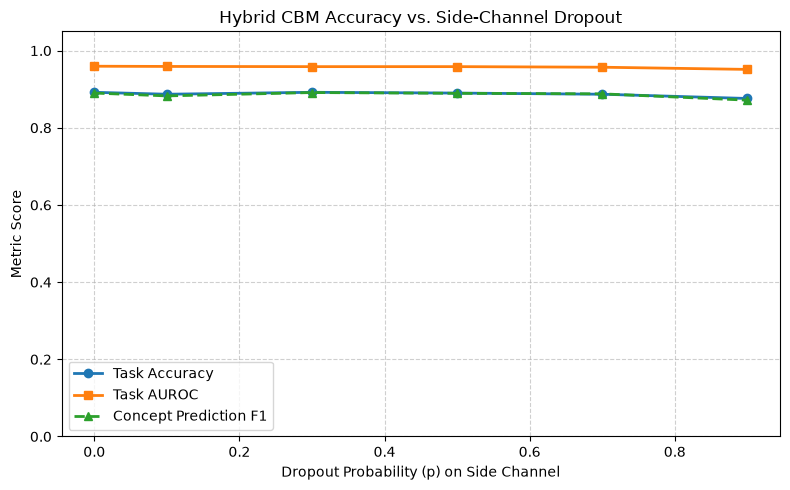

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(results_summary['dropout'], results_summary['accuracy'], marker='o', label='Task Accuracy', linewidth=2)
plt.plot(results_summary['dropout'], results_summary['auroc'], marker='s', label='Task AUROC', linewidth=2)
plt.plot(results_summary['dropout'], results_summary['concept_f1'], marker='^', label='Concept Prediction F1', linestyle='--', linewidth=2)

plt.title("Hybrid CBM Accuracy vs. Side-Channel Dropout")
plt.xlabel("Dropout Probability (p) on Side Channel")
plt.ylabel("Metric Score")
plt.ylim(0.0, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

# 1. Map only the valid bottleneck / hybrid models to compare
models_to_compare = {
    "Independent CBM": cbm_model, 
    "Hybrid CBM (Standard)": hybrid_cbm,
}

for p, model_instance in dropout_models.items():
    models_to_compare[f"Hybrid + Dropout (p={p})"] = model_instance

comparative_summary = {}
print("--- Comparing Steerability Across Models ---")
for model_name, model in models_to_compare.items():
    if model is None:
        print(f"Skipping {model_name} (not found in workspace).")
        continue
        
    print(f"\nEvaluating Interventions for: {model_name}")
    model.eval()
    
    intervention_results = {}
    concept_sums = {j: 0.0 for j in range(10)}
    flip_sums = {j: 0.0 for j in range(10)}
    total_batches = 0
    
    # Run evaluation and interventions batch-by-batch to avoid tensor size mismatches
    with torch.no_grad():
        for images, targets in test_loader_hybrid:
            images = images.to(device)
            total_batches += 1
            
            # 1. Forward pass (handles both single output and tuple output)
            out = model(images)
            if isinstance(out, tuple):
              final_logits, c_probs = out
            else:
              final_logits = out
              c_probs = torch.sigmoid(model.concept_predictor(images))
            
            # 2. Extract features if it's a hybrid model (IndependentCBM has no side-channel)
            batch_features = (
                model.extracted_features.clone()
                if not isinstance(model, IndependentCBM)
                and model.extracted_features is not None
                else None
            )
                
            orig_task_probs = torch.sigmoid(final_logits)
            orig_preds = (orig_task_probs >= 0.5)
            
            # 2. Perform concept interventions per concept j on this batch
            for j in range(10):
                intervened_concepts = c_probs.clone()
                intervened_concepts[:, j] = 1.0 - intervened_concepts[:, j]
                
                if isinstance(model, IndependentCBM):
                    new_logits = model.c_to_y(intervened_concepts.to(device))
                    new_task_probs = torch.sigmoid(new_logits)
                elif isinstance(model, HybridCBM) or isinstance(model, HybridCBMWithDropout):
                    f_c_logits = model.f_c(intervened_concepts.to(device))
                    if batch_features is not None:
                        s_x_logits = model.s_x(batch_features)
                        new_logits = f_c_logits + s_x_logits
                    else:
                        new_logits = f_c_logits
                    new_task_probs = torch.sigmoid(new_logits)
                
                # Measure batch metrics
                prob_changes = torch.abs(new_task_probs.cpu() - orig_task_probs.cpu())
                concept_sums[j] += prob_changes.mean().item()
                
                new_preds = (new_task_probs.cpu() >= 0.5)
                fraction_flipped = (orig_preds.cpu() != new_preds).float().mean().item()
                flip_sums[j] += fraction_flipped

    # Average metrics across all batches
    for j in range(10):
        avg_prob_change = concept_sums[j] / total_batches
        fraction_flipped = flip_sums[j] / total_batches
        intervention_results[f"Concept_{j}"] = {
            "avg_prob_change": avg_prob_change,
            "fraction_flipped": fraction_flipped
        }
        
    # Rank concepts
    ranked_concepts = sorted(intervention_results.items(), key=lambda x: x[1]["avg_prob_change"], reverse=True)
    overall_steerability = np.mean([m["avg_prob_change"] for _, m in ranked_concepts])
    overall_flip_rate = np.mean([m["fraction_flipped"] for _, m in ranked_concepts])
    
    comparative_summary[model_name] = {
        "Mean Prob Change (Steerability)": overall_steerability,
        "Mean Flip Rate (%)": overall_flip_rate * 100,
        "Top Concept": ranked_concepts[0][0],
        "Top Effect": ranked_concepts[0][1]["avg_prob_change"]
    }
    
    print(f"--> Done [{model_name}] | Mean Prob Change: {overall_steerability:.4f} | Flip Rate: {overall_flip_rate*100:.1f}%")

# Output final table
summary_df = pd.DataFrame(comparative_summary).T
print(summary_df.to_string())

--- Comparing Steerability Across Models ---

Evaluating Interventions for: Independent CBM
--> Done [Independent CBM] | Mean Prob Change: 0.0504 | Flip Rate: 22.1%

Evaluating Interventions for: Hybrid CBM (Standard)
--> Done [Hybrid CBM (Standard)] | Mean Prob Change: 0.0077 | Flip Rate: 0.8%

Evaluating Interventions for: Hybrid + Dropout (p=0.0)
--> Done [Hybrid + Dropout (p=0.0)] | Mean Prob Change: 0.0119 | Flip Rate: 1.1%

Evaluating Interventions for: Hybrid + Dropout (p=0.1)
--> Done [Hybrid + Dropout (p=0.1)] | Mean Prob Change: 0.0101 | Flip Rate: 0.7%

Evaluating Interventions for: Hybrid + Dropout (p=0.3)
--> Done [Hybrid + Dropout (p=0.3)] | Mean Prob Change: 0.0070 | Flip Rate: 0.5%

Evaluating Interventions for: Hybrid + Dropout (p=0.5)
--> Done [Hybrid + Dropout (p=0.5)] | Mean Prob Change: 0.0129 | Flip Rate: 1.4%

Evaluating Interventions for: Hybrid + Dropout (p=0.7)
--> Done [Hybrid + Dropout (p=0.7)] | Mean Prob Change: 0.0136 | Flip Rate: 1.5%

Evaluating Interve